In [33]:
from pathlib import Path
ROOT = Path('/home/smak/koulu/dsp/DSP-Course-2026/Audio_Course_Student_Package')  # folder that contains data/manifest.csv
assert (ROOT/'data/manifest.csv').exists()

In [34]:
import os, json, time, re, unicodedata, importlib.metadata as meta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display
import soundfile as sf
from scipy import signal
from IPython.display import Audio, display

os.environ['CUDA_VISIBLE_DEVICES']='-1'
os.environ['TF_USE_LEGACY_KERAS']='1'
SEED=42
rng=np.random.default_rng(SEED)
FS=16000
DATA=ROOT/'data'
OUT=ROOT/'results'; OUT.mkdir(exist_ok=True)
FIG=OUT/'figures'; FIG.mkdir(exist_ok=True)

def load_audio(path, target_rate=FS):
    x, rate = sf.read(str(path),dtype='float32',always_2d=True)
    x=x.mean(axis=1)  # This course uses mono. Opposite-polarity channels can cancel.
    assert len(x)>0 and np.isfinite(x).all(), 'Invalid audio.'
    if rate != target_rate:
        x=librosa.resample(x,orig_sr=rate,target_sr=target_rate)
    return np.asarray(x,dtype=np.float32)

def play(x, rate=FS):
    display(Audio(np.asarray(x),rate=rate,normalize=False))

def save_plot(name):
    plt.tight_layout(); plt.savefig(FIG/name,dpi=140); plt.show()

def spectrum(x, fs=FS):
    a=np.asarray(x,dtype=float); a=a-a.mean()
    s=np.abs(np.fft.rfft(a*np.hanning(len(a))))
    return np.fft.rfftfreq(len(a),1/fs),20*np.log10(np.maximum(s/max(s.max(),1e-12),1e-6))

def inspect(x, fs=FS, title='Audio', name='inspection.png'):
    f,d=spectrum(x,fs)
    fig,ax=plt.subplots(2,1,figsize=(9,5))
    ax[0].plot(np.arange(len(x))/fs,x,lw=.7);ax[0].set(title=title,xlabel='Time (s)',ylabel='Amplitude')
    ax[1].plot(f,d);ax[1].set(xlabel='Frequency (Hz)',ylabel='Relative magnitude (dB)',xlim=(0,min(8000,fs/2)),ylim=(-80,3))
    save_plot(name)

speech=load_audio(DATA/'demo/05_speech.wav')
print('Speech duration:',len(speech)/FS,'seconds')
play(speech)


Speech duration: 11.0 seconds


### Assignment
## Option C - Analyse an environmental sound

### Steps 1 & 2

['dog' 'rain' 'crackling_fire' 'clock_tick']
classification/1-17150-A-12.wav 5.00 s


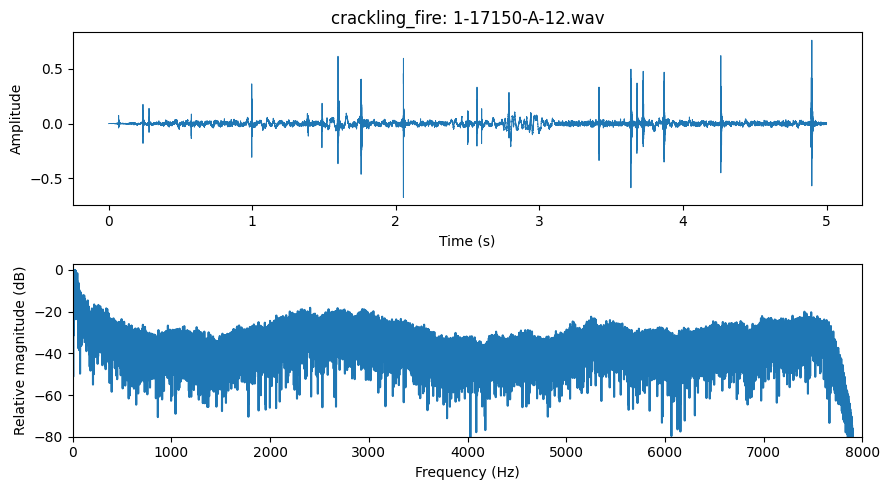

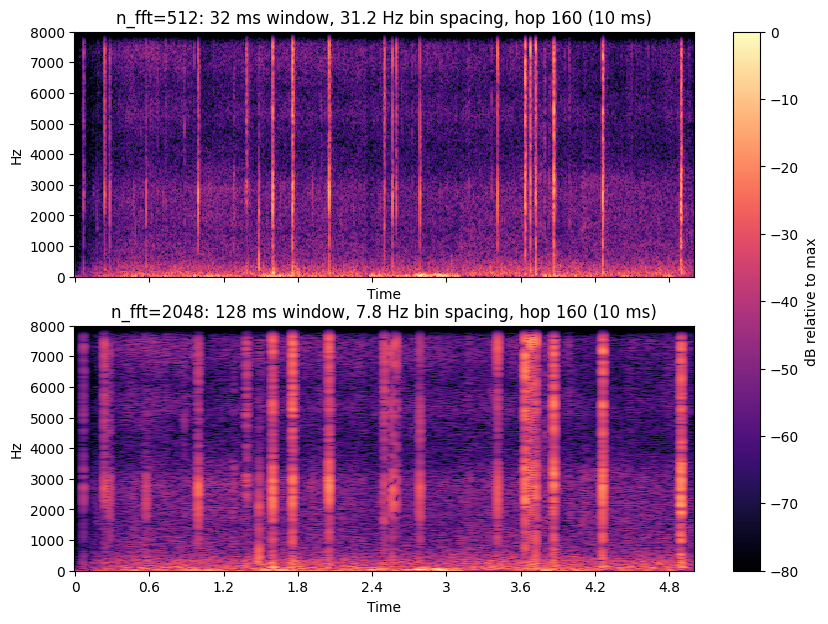

In [35]:
manifest = pd.read_csv(DATA/'manifest.csv')
print(manifest.label.unique())
row = manifest[manifest.label=='crackling_fire'].iloc[0]    # I choose crackling_fire as the audio clip
x = load_audio(DATA/row.file)
print(row.file, f'{len(x)/FS:.2f} s')
play(x)
inspect(x, title=f'{row.label}: {Path(row.file).name}', name='task_inspection.png')

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, nfft in zip(axes, [512, 2048]):
    S = np.abs(librosa.stft(x, n_fft=nfft, hop_length=160, window='hann'))
    db = librosa.amplitude_to_db(S, ref=np.max)
    im = librosa.display.specshow(db, sr=FS, hop_length=160, x_axis='time', y_axis='linear',
                                  ax=ax, vmin=-80, vmax=0)
    ax.set(title=f'n_fft={nfft}: {1000*nfft/FS:.0f} ms window, {FS/nfft:.1f} Hz bin spacing, hop 160 (10 ms)',
           ylim=(0, 8000))
    
fig.colorbar(im, ax=axes, label='dB relative to max')
plt.savefig(FIG/'task_window_compare.png', dpi=140, bbox_inches='tight'); plt.show()

### Step 3

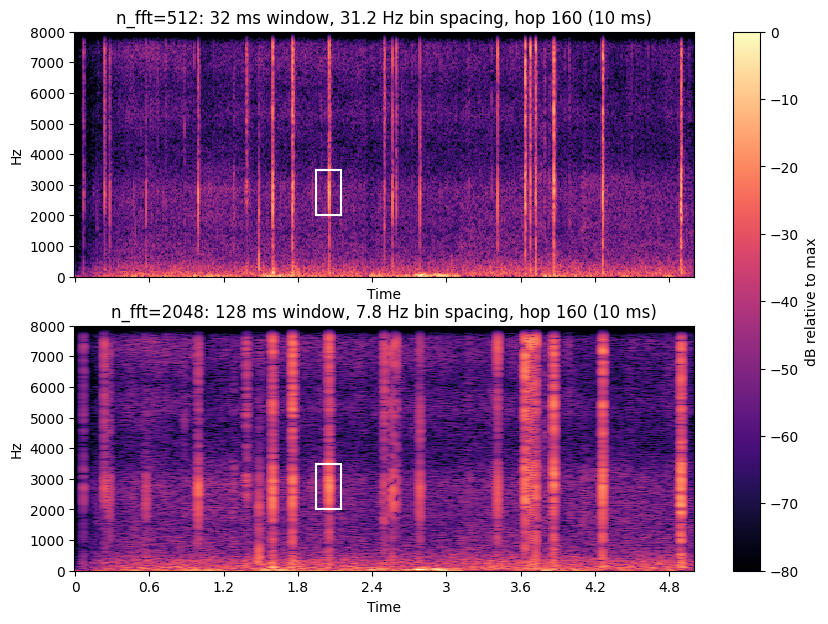

Strongest component in 2000–3500 Hz during 1.95–2.15 s: 2730 Hz


In [36]:
t0, t1 = 1.95, 2.15
f0, f1 = 2000, 3500
from matplotlib.patches import Rectangle
for ax in axes:
    ax.add_patch(Rectangle((t0, f0), t1-t0, f1-f0, fill=False, ec='white', lw=1.5))
display(fig)

seg = x[int(t0*FS):int(t1*FS)]
f, d = spectrum(seg)
band = (f >= f0) & (f <= f1)
print(f'Strongest component in {f0}–{f1} Hz during {t0}–{t1} s: {f[band][d[band].argmax()]:.0f} Hz')

### Step 4
2.3-3.2 s, 0-8 kHz: a cluster of smaller crackles, with distinct impulses at about 2.55, 2.6 and 2.8 s and denser low-level bursts around 2.7-3.0 s. Like the larger crackles, they are broadband, extending up to the 7.8 kHz resampling cut-off.

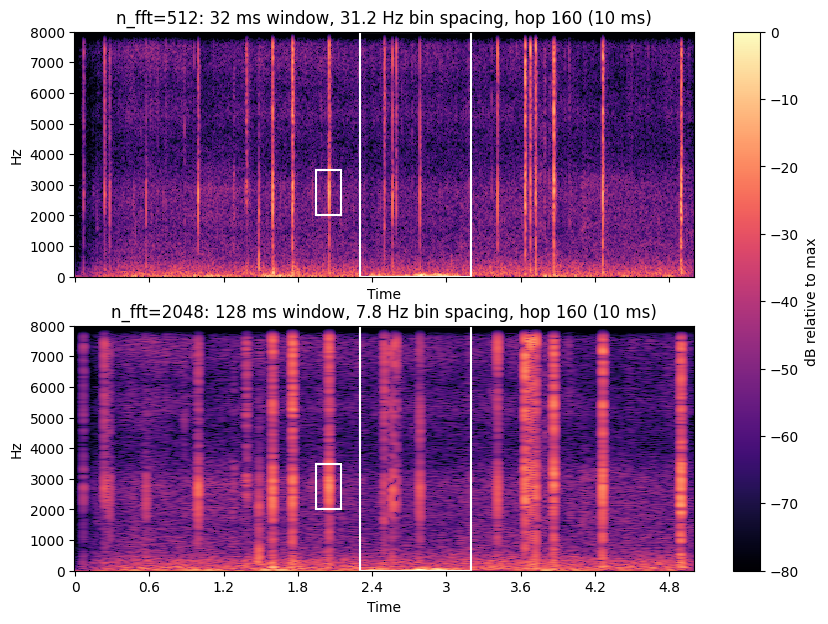

In [37]:
t0, t1 = 2.3, 3.2
f0, f1 = 0, 8000
from matplotlib.patches import Rectangle
for ax in axes:
    ax.add_patch(Rectangle((t0, f0), t1-t0, f1-f0, fill=False, ec='white', lw=1.5))
display(fig)

seg = x[int(t0*FS):int(t1*FS)]
f, d = spectrum(seg)
band = (f >= f0) & (f <= f1)

### Step 5

In the 512 sample, 32 ms window spectrogram, the shorter window localises crackles within a few frames and keeps them separated.
The 128 ms window spreads every impulse over 128 ms, and the events merge together, showing as a more hazy version of the other spectrogram.

The analysis uses audio resampled to 16 kHz, so nothing above 8 kHz is visible. The spectrum is still near its maximum level at 7–7.5 kHz before the anti-alias roll-off at 7.6 kHz, which indicates that some of the crackle energy is above the analysed band.